# HSA_Cam_B_010.py
This file uses the LHHW_Model of kinetics to determine kinetic parameters and an optimal next experiment.

HSA_Cam_B_006.py is the model. This uses homoscedastic noise. Additionally, most parameters are at their expected values to investigate the behavior of the KL Divergence

### Plan:
* Instantiate the model on a single proposed temperature 
* Run inference
* Check that the HDI is reasonable
* calculate the KLD for the already observed temperature and a new proposed temperature


### Results:


In [1]:
import jax.numpy as jnp
import jax
import numpy as np
import matplotlib.pyplot as plt

import pymc as pm
import pytensor

import arviz as az
from scipy.optimize import minimize

In [2]:
from HSA_Cam_B_006 import (
    SIDX,
    TRUE_PARAMS,
    _kinetics_model,
    input_p,
    bmodel,
)

# pytensor.config.mode = "JAX"

In [3]:
def post_model_over_T(proposal, idata, key="posterior"):

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        "k0": idata[key]["k0"].values.reshape(1, -1),
        "Ea_k": idata[key]["Ea_k"].values.reshape(1, -1),
        "A_oh": idata[key]["A_oh"].values.reshape(1, -1),
        "dH_oh": idata[key]["dH_oh"].values.reshape(1, -1),
        "A_h2": idata[key]["A_h2"].values.reshape(1, -1),
        "dH_h2": idata[key]["dH_h2"].values.reshape(1, -1),
        "A_mix": idata[key]["A_mix"].values.reshape(1, -1),
        "dH_mix": idata[key]["dH_mix"].values.reshape(1, -1),
    }

    test_res = _kinetics_model(**test_params)
    return test_res


def true_model_over_T(proposal):
    true_res_T = _kinetics_model(
        input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        jnp.linspace(500.0, 600.0, 100).reshape(-1, 1),
        *TRUE_PARAMS.values(),
    )
    return true_res_T

In [4]:
def post_model_at_proposal(proposal, idata, key="posterior", n_samples=5):

    param_samples = az.extract(idata, group=key, num_samples=n_samples)

    test_params = {
        "p_i": input_p(
            jnp.array(proposal[1]).reshape(1, 1),
            jnp.array(proposal[2]).reshape(1, 1),
            jnp.array(proposal[3]).reshape(1, 1),
            jnp.array(proposal[4]).reshape(1, 1),
        ).reshape(1, -1),
        "T": jnp.array(proposal[0]).reshape(1, 1),
        "k0": param_samples["k0"].values.reshape(1, -1),
        "Ea_k": param_samples["Ea_k"].values.reshape(1, -1),
        "A_oh": param_samples["A_oh"].values.reshape(1, -1),
        "dH_oh": param_samples["dH_oh"].values.reshape(1, -1),
        "A_h2": param_samples["A_h2"].values.reshape(1, -1),
        "dH_h2": param_samples["dH_h2"].values.reshape(1, -1),
        "A_mix": param_samples["A_mix"].values.reshape(1, -1),
        "dH_mix": param_samples["dH_mix"].values.reshape(1, -1),
    }

    r = _kinetics_model(**test_params)
    obs_r = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return obs_r

In [5]:
def plot_post_model_at_proposal(proposal, test_res, true_res, Ts):
    plt.plot(
        Ts,
        test_res.mean(axis=1),
    )
    plt.plot(
        Ts,
        true_res.squeeze(),
        color="black",
        linestyle="--",
    )
    plt.fill_between(
        x=Ts,
        y1=np.percentile(test_res, 2.5, axis=1),
        y2=np.percentile(test_res, 97.5, axis=1),
        alpha=0.3,
        zorder=0,
    )
    ax = plt.gca()
    ax.text(
        0.05,
        0.95,
        f"pred. @ p={proposal[1]:.2f}, F= {proposal[2]:.2f}, C= {proposal[3]:.2f}, H2= {proposal[4]:.2f}",
        transform=ax.transAxes,
        fontsize=10,
    )
    ax2 = ax.twinx()
    ax2.plot(
        Ts,
        (np.percentile(test_res, 97.5, axis=1) - np.percentile(test_res, 2.5, axis=1))
        / np.mean(test_res, axis=1),
        color="orange",
    )

In [6]:
def observe_at_proposal(proposals):
    T = jnp.array([proposals[:, 0]], dtype=jnp.float32).reshape(-1, 1)
    p = jnp.array([proposals[:, 1]], dtype=jnp.float32).reshape(-1, 1)
    c2h = jnp.array([proposals[:, 2]], dtype=jnp.float32).reshape(-1, 1)
    f = jnp.array([proposals[:, 3]], dtype=jnp.float32).reshape(-1, 1)
    c2i = jnp.array([proposals[:, 4]], dtype=jnp.float32).reshape(-1, 1)

    p_i = input_p(p, c2h, f, c2i)

    r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
    r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
    return T, p, c2h, f, c2i, r_obs

In [7]:
T = jnp.array([560, 570, 580], dtype=jnp.float32).reshape(-1, 1)
p = jnp.array([4, 5, 6], dtype=jnp.float32).reshape(-1, 1)
c2h = jnp.array([1], dtype=jnp.float32).reshape(-1, 1)
f = jnp.array([1000], dtype=jnp.float32).reshape(-1, 1)
c2i = jnp.array([0.5], dtype=jnp.float32).reshape(-1, 1)

p_i = input_p(p, c2h, f, c2i)
print(p_i)

r = _kinetics_model(p_i, T, *TRUE_PARAMS.values())
print(r)
r_obs = r + jax.random.normal(jax.random.PRNGKey(1), r.shape) * 1e-5
print(r_obs)

[[9.99750078e-01 9.99750078e-01 0.00000000e+00 9.99750078e-04
  1.99950016e+00]
 [1.24968760e+00 1.24968760e+00 0.00000000e+00 1.24968760e-03
  2.49937519e+00]
 [1.49962512e+00 1.49962512e+00 0.00000000e+00 1.49962512e-03
  2.99925023e+00]]
[[7.61192633e-05]
 [1.16399861e-04]
 [1.72598760e-04]]
[[8.56923350e-05]
 [1.06700571e-04]
 [1.82669424e-04]]


In [8]:
def max_func(x, idata, key="posterior"):
    T = x[0].reshape(1, 1)
    p = x[1].reshape(1, 1)
    c2h = x[2].reshape(1, 1)
    f = x[3].reshape(1, 1)
    c2i = x[4].reshape(1, 1)
    p_i = input_p(p, c2h, f, c2i)
    res = _kinetics_model(
        p_i,
        T,
        idata[key]["k0"].values.reshape(1, -1),
        idata[key]["Ea_k"].values.reshape(1, -1),
        idata[key]["A_oh"].values.reshape(1, -1),
        idata[key]["dH_oh"].values.reshape(1, -1),
        idata[key]["A_h2"].values.reshape(1, -1),
        idata[key]["dH_h2"].values.reshape(1, -1),
        idata[key]["A_mix"].values.reshape(1, -1),
        idata[key]["dH_mix"].values.reshape(1, -1),
    )
    HDI = jnp.percentile(res, 97.5) - jnp.percentile(res, 2.5)
    return -HDI

In [9]:
def detect_transformed_keys(model: pm.Model) -> dict[str, str]:
    """
    Inspect model.initial_point() to find whether a variable uses a transformed name.
    Returns mapping constrained_name -> key_expected_by_compiled_logp.
    Heuristics cover common transforms: log (-> name_log__), logit (-> name_interval__),
    but in general we fall back to the same name if present.
    """
    init = model.initial_point()
    mapping = {}
    for name in model.named_vars:
        constrained = name
        if constrained in init:
            mapping[constrained] = constrained
        elif f"{constrained}_log__" in init:
            mapping[constrained] = f"{constrained}_log__"
        elif f"{constrained}_interval__" in init:
            mapping[constrained] = f"{constrained}_interval__"
        else:
            # fallback: try to find any init key that contains the var name
            found = [k for k in init.keys() if k.startswith(constrained)]
            mapping[constrained] = found[0] if found else constrained
    return mapping


def build_point_for_compiled(mapping: dict[str, str], sample_dict):
    """
    Given a mapping constrained->compiled_key and a sample of constrained vars (sample_dict),
    return a point dict suitable for compiled_logp. For common transforms we apply inverse transform:
      - If compiled_key endswith '_log__' -> pass np.log(value)
      - If compiled_key endswith '_interval__' -> pass logit(value) = log(p/(1-p))
    Otherwise pass the raw constrained value.
    """

    def safe_log(x):
        return np.log(np.maximum(x, 1e-300))

    def safe_logit(x):
        x = np.clip(x, 1e-12, 1 - 1e-12)
        return np.log(x / (1 - x))

    point = {}
    for constrained_name, compiled_key in mapping.items():
        if constrained_name not in sample_dict:
            continue  # maybe a deterministic / not in sample
        val = sample_dict[constrained_name]
        if compiled_key.endswith("_log__"):
            point[compiled_key] = safe_log(val)
        elif compiled_key.endswith("_interval__"):
            point[compiled_key] = safe_logit(val)
        else:
            point[compiled_key] = val
    return point

In [41]:
def KL_divergence(model, x, y, x_new, idata, key="posterior", n_hyp_samples=5):
    base_logp = model.compile_logp()
    base_mapping = detect_transformed_keys(model)

    # draw the hypothetical samples from the posterior
    y_new = post_model_at_proposal(
        x_new,
        idata,
        key=key,
        n_samples=n_hyp_samples,
    ).squeeze()
    print("Hypothetical samples shape:", y_new.shape)
    klds = np.zeros(n_hyp_samples)
    for i in range(n_hyp_samples):
        print(f"Hypothetical sample {i + 1}/{n_hyp_samples}")
        # append the hypothetical observation to the existing data
        # generate the new parameters at which to observe
        x_adj = jnp.vstack([x, x_new])
        # generate the new actual parameters, omit the observed data though
        T_adj, p_adj, c2h_adj, f_adj, c2i_adj, _ = observe_at_proposal(x_adj)
        # append the hypothetical observation to the existing data
        print(y.shape, y_new[i].shape)
        y_adj = jnp.vstack([y, y_new[i].reshape(1, 1)])
        # build the adjusted model
        adj_model = bmodel(
            (
                np.asarray(T_adj),
                np.asarray(p_adj),
                np.asarray(c2h_adj),
                np.asarray(f_adj),
                np.asarray(c2i_adj),
            ),
            np.asarray(y_adj),
        )
        # very quickly and imprecisely sample from the adjusted model
        with adj_model:
            approx = pm.fit(
                n=50000,
                method="advi",
                # obj_optimizer=pm.adam(learning_rate=0.01),
            )
            adj_trace = approx.sample(1000)
        # build the adjusted logp function
        adj_logp = adj_model.compile_logp()
        adj_mapping = detect_transformed_keys(adj_model)
        # extract the posterior samples from the adjusted model
        posterior_theta_samples = az.extract(
            adj_trace,
            group="posterior",
            var_names=[
                "~y_hat",
            ],  # exclude predictive and deterministic variables
        )
        post_dict = {}
        for var in posterior_theta_samples.data_vars:
            post_dict[var] = posterior_theta_samples[var].values
        # compute the KL divergence component for this hypothetical sample
        logp_old = np.empty(500)
        logp_new = np.empty(500)
        for j in range(500):
            sample_dict = {k: v[j] for k, v in post_dict.items()}
            point_new = build_point_for_compiled(adj_mapping, sample_dict)
            point_old = build_point_for_compiled(base_mapping, sample_dict)
            logp_new[j] = adj_logp(point_new)
            logp_old[j] = base_logp(point_old)
        kl_div_i = np.mean(logp_new - logp_old)
        klds[i] = kl_div_i

    return np.mean(klds)

generate the first 4 points on purpose

In [11]:
proposals = np.array(
    [
        [555.0, 4.0, 0.5, 1000.0, 0.5],
        [555.0, 20.0, 0.5, 1000.0, 0.5],
    ]
)

In [12]:
T, p, c2h, f, c2i, r_obs = observe_at_proposal(proposals)
model = bmodel(
    (
        np.asarray(T),
        np.asarray(p),
        np.asarray(c2h),
        np.asarray(f),
        np.asarray(c2i),
    ),
    np.asarray(r_obs),
)
with model:
    prior_idata = pm.sample_prior_predictive(samples=1000)
    idata = pm.sample(
        tune=1000,
        draws=4000,
        chains=4,
        target_accept=0.9,
        return_inferencedata=True,
    )

Sampling: [A_h2, A_mix, A_oh, Ea_k, LH2, dH_h2, dH_mix, dH_oh, k0, sigma_r]
Initializing NUTS using jitter+adapt_diag...
c:\Users\hanne\anaconda3\envs\pymc_env\Lib\site-packages\pytensor\link\c\cmodule.py:2968: UserWarning: PyTensor could not link to a BLAS installation. Operations that might benefit from BLAS will be severely degraded.
This usually happens when PyTensor is installed via pip. We recommend it be installed via conda/mamba/pixi instead.
Alternatively, you can use an experimental backend such as Numba or JAX that perform their own BLAS optimizations, by setting `pytensor.config.mode == 'NUMBA'` or passing `mode='NUMBA'` when compiling a PyTensor function.
For more options and details see https://pytensor.readthedocs.io/en/latest/troubleshooting.html#how-do-i-configure-test-my-blas-library
  warnings.warn(
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [k0, Ea_k, A_oh, dH_oh, A_h2, dH_h2, A_mix, dH_mix, sigma_r]


Output()

Sampling 4 chains for 1_000 tune and 4_000 draw iterations (4_000 + 16_000 draws total) took 38 seconds.
There were 2 divergences after tuning. Increase `target_accept` or reparameterize.


In [13]:
idata.prior = prior_idata.prior

array([[<Axes: >, <Axes: >, <Axes: xlabel='Ea_k'>]], dtype=object)

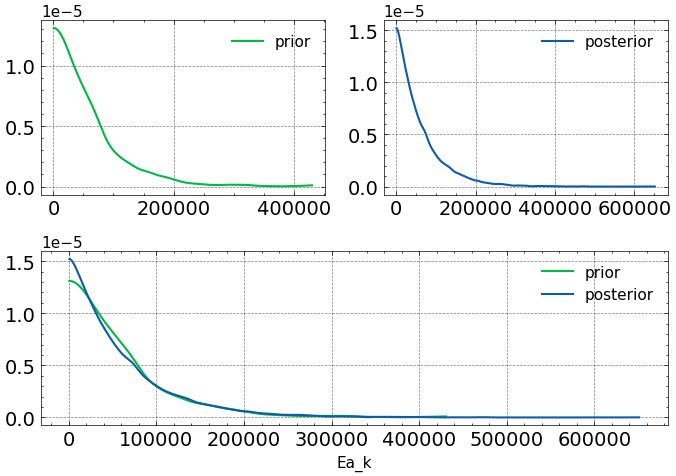

In [14]:
import ICIW_Plots

plt.style.use("ICIWstyle")
az.plot_dist_comparison(idata, var_names=["Ea_k"], figsize=(7, 5))

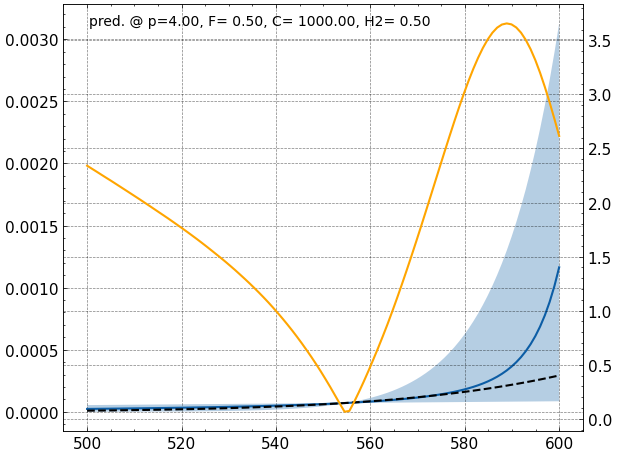

In [15]:
i = 0
Ts = jnp.linspace(500.0, 600.0, 100)
# test_res = post_model_over_T(proposals[i], prior_idata, key="prior")
r = post_model_over_T(proposals[i], idata, key="posterior")
true_res_T = true_model_over_T(proposals[i])
plot_post_model_at_proposal(proposals[i], r, true_res_T, Ts)

## test the KL divergence calculation

In [44]:
new_proposal = jnp.array(
    [580.0, 4.0, 0.5, 1000.0, 0.5],
)
KL_divergence(
    model,
    proposals[:, :],
    r_obs,
    new_proposal.squeeze(),
    idata,
    key="posterior",
    n_hyp_samples=5,
)

Hypothetical samples shape: (5,)
Hypothetical sample 1/5
(2, 1) ()


Output()

Finished [100%]: Average Loss = 19,769


Hypothetical sample 2/5
(2, 1) ()


Output()

...

Finished [100%]: Average Loss = 6.162e+11


Hypothetical sample 5/5
(2, 1) ()


Output()

Finished [100%]: Average Loss = 21,959


np.float64(-2442283.045859947)

In [43]:
new_proposal = jnp.array(
    [555.0, 4.0, 0.5, 1000.0, 0.5],
)
KL_divergence(
    model,
    proposals[:, :],
    r_obs,
    new_proposal.squeeze(),
    idata,
    key="posterior",
    n_hyp_samples=5,
)

Hypothetical samples shape: (5,)
Hypothetical sample 1/5
(2, 1) ()


Output()

Finished [100%]: Average Loss = 19,501


Hypothetical sample 2/5
(2, 1) ()


Output()

...

Finished [100%]: Average Loss = 20,258


Hypothetical sample 5/5
(2, 1) ()


Output()

Finished [100%]: Average Loss = 20,212


np.float64(9.097850881701778)